# Дослідження ринку нерухомості: Ames Housing (2006–2010)

**Курсова робота** з дисципліни «Мови програмування для аналізу даних».

**Мета:** визначити, які характеристики будинків і умови продажу формують ціну житла в м. Еймс (штат Айова, США) у 2006–2010 роках.

**Дослідницькі питання**
1. Як ціна відрізняється між районами і які райони найдорожчі?
2. Як ціна залежить від площі, якості та віку будинку?
3. Як змінювалися ціни та кількість продажів у часі, зокрема в період кризи 2008–2009 років?
4. Чи впливають на ціну умови продажу (`SaleCondition`) і тип будинку?
5. Чи є аномальні угоди, що спотворюють результати?

**Дані:** Ames Housing (Kaggle, *House Prices – Advanced Regression Techniques*), файл `train.csv`. Опис ознак — `data/raw/data_description.txt`.

## 0. Запуск у Google Colab (лише для Colab)

In [1]:
# У Colab ноутбук відкривається без решти файлів проєкту, тому клонуємо репозиторій.
# Локально (Jupyter) ця комірка нічого не робить.
import os
if "COLAB_GPU" in os.environ or os.path.exists("/content"):
    if not os.path.exists("/content/ames-housing-analysis"):
        !git clone https://github.com/Denis8870/ames-housing-analysis.git /content/ames-housing-analysis
    %cd /content/ames-housing-analysis/notebooks

## 1. Підготовка середовища

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid")

RAW_PATH = Path("../data/raw/train.csv")
PROCESSED_PATH = Path("../data/processed/ames_clean.csv")
FIG_DIR = Path("../results/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

## 2. Завантаження даних

In [3]:
df_raw = pd.read_csv(RAW_PATH)
print(f"Записів: {df_raw.shape[0]}, ознак: {df_raw.shape[1]}")
df_raw.head()

Записів: 1460, ознак: 81


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.00,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.00,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,"2,003.00",RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.00,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.00,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,"1,976.00",RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.00,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.00,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,"2,001.00",RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.00,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.00,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,"1,998.00",Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.00,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.00,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,"2,000.00",RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 3. Первинне дослідження

Перевіряємо розмір таблиці, типи змінних і описову статистику цільового показника `SalePrice` (ціна продажу, USD).

In [4]:
print("Типи змінних:")
print(df_raw.dtypes.astype(str).value_counts())
print()
df_raw.info(max_cols=0)

Типи змінних:
str        43
int64      35
float64     3
Name: count, dtype: int64

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Columns: 81 entries, Id to SalePrice
dtypes: float64(3), int64(35), str(43)
memory usage: 924.0 KB


In [5]:
df_raw["SalePrice"].describe()

count     1,460.00
mean    180,921.20
std      79,442.50
min      34,900.00
25%     129,975.00
50%     163,000.00
75%     214,000.00
max     755,000.00
Name: SalePrice, dtype: float64

In [6]:
# Кількість продажів за роками та унікальних районів
print(df_raw["YrSold"].value_counts().sort_index())
print("\nУнікальних районів:", df_raw["Neighborhood"].nunique())

YrSold
2006    314
2007    329
2008    304
2009    338
2010    175
Name: count, dtype: int64

Унікальних районів: 25


**Висновок.** Таблиця містить 1460 продажів і 81 ознаку: числові (площі, рік побудови, кількість кімнат) та категоріальні (район, тип будинку, умови продажу). Часова ознака — `YrSold` і `MoSold` (2006–2010). Для групування придатні `Neighborhood`, `BldgType`, `SaleCondition`, `YrSold`; ключ — `Id`.

## 4. Попереднє опрацювання даних

### 4.1. Дублікати

In [7]:
dup_full = df_raw.duplicated().sum()
dup_id = df_raw["Id"].duplicated().sum()
print(f"Повних дублікатів: {dup_full}")
print(f"Дублікатів за Id: {dup_id}")

Повних дублікатів: 0
Дублікатів за Id: 0


### 4.2. Пропущені значення

Згідно з `data_description.txt`, у багатьох категоріальних ознаках значення `NA` означає **відсутність об'єкта** (немає басейну, гаража, підвалу), а не втрачені дані. Pandas за замовчуванням читає рядок `NA` як `NaN`, тому спершу розділимо «структурні» пропуски й справжні.

In [8]:
missing_before = df_raw.isna().sum()
missing_before = missing_before[missing_before > 0].sort_values(ascending=False)
summary_before = pd.DataFrame({
    "Пропусків": missing_before,
    "Частка, %": (missing_before / len(df_raw) * 100).round(1),
})
summary_before

,Пропусків,"Частка, %"
PoolQC,1453,99.50
MiscFeature,1406,96.30
Alley,1369,93.80
Fence,1179,80.80
MasVnrType,872,59.70
FireplaceQu,690,47.30
LotFrontage,259,17.70
GarageType,81,5.50
GarageYrBlt,81,5.50
GarageFinish,81,5.50


In [9]:
# Ознаки, де NA = «об'єкта немає» (за data_description.txt)
none_means_absent = [
    "Alley", "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
    "FireplaceQu", "GarageType", "GarageFinish", "GarageQual", "GarageCond",
    "PoolQC", "Fence", "MiscFeature",
]
# Додатково: MasVnrType — у даних значення "None" (немає облицювання) прочиталось як NaN
none_means_absent_all = none_means_absent + ["MasVnrType"]

df = df_raw.copy()
for col in none_means_absent_all:
    df[col] = df[col].fillna("None")

# Пов'язана числова ознака: якщо облицювання немає, його площа = 0
df["MasVnrArea"] = df["MasVnrArea"].fillna(0)

# Рік побудови гаража: пропуск там, де гаража немає. Лишаємо NaN
# (підставляти рік було б некоректно), але додаємо позначку наявності гаража.
df["HasGarage"] = (df["GarageType"] != "None").astype(int)

# Електрика: 1 справжній пропуск -> мода (категорія, що переважає)
df["Electrical"] = df["Electrical"].fillna(df["Electrical"].mode()[0])

# LotFrontage: 259 справжніх пропусків (≈18%). Заповнюємо медіаною по району,
# бо ширина ділянки типова для району; видаляти 18% записів недоцільно.
df["LotFrontage"] = df.groupby("Neighborhood")["LotFrontage"].transform(lambda s: s.fillna(s.median()))
df["LotFrontage"] = df["LotFrontage"].fillna(df["LotFrontage"].median())

In [10]:
missing_after = df.isna().sum()
missing_after = missing_after[missing_after > 0]
print("Залишилось пропусків (лише GarageYrBlt — гаража немає):")
print(missing_after)
print()
print(f"Пропусків усього: до = {int(df_raw.isna().sum().sum())}, після = {int(df.isna().sum().sum())}")
print(f"Колонок із пропусками: до = {int((df_raw.isna().sum() > 0).sum())}, після = {int((df.isna().sum() > 0).sum())}")

Залишилось пропусків (лише GarageYrBlt — гаража немає):
GarageYrBlt    81
dtype: int64

Пропусків усього: до = 7829, після = 81
Колонок із пропусками: до = 19, після = 1


**Висновок.** Більшість пропусків були не втратою даних, а кодом «немає»: їх замінено на категорію `"None"`. Справжніх пропусків було два типи: `LotFrontage` (заповнено медіаною по району) і `Electrical` (1 запис, заповнено модою). `GarageYrBlt` лишено порожнім для будинків без гаража, а наявність гаража зафіксовано ознакою `HasGarage`.

### 4.3. Типи даних

In [11]:
# MSSubClass — код типу будинку, а не число; YrSold/MoSold беруть участь у групуванні як категорії
df["MSSubClass"] = df["MSSubClass"].astype("category")

# Дата продажу для аналізу динаміки
df["SaleDate"] = pd.to_datetime(
    dict(year=df["YrSold"], month=df["MoSold"], day=1)
)
df[["YrSold", "MoSold", "SaleDate"]].head()

,YrSold,MoSold,SaleDate
0,2008,2,2008-02-01
1,2007,5,2007-05-01
2,2008,9,2008-09-01
3,2006,2,2006-02-01
4,2008,12,2008-12-01


`MSSubClass` — це код (20, 30, 60…), арифметика з ним не має сенсу, тому його перетворено на категорію. Із `YrSold` і `MoSold` сформовано `SaleDate` для аналізу динаміки.

### 4.4. Викиди

Викиди не завжди є помилками, тому їх **не видаляємо автоматично**: спершу оцінюємо кількість за методом міжквартильного розмаху (IQR) та розглядаємо найпідозріліші записи.

In [12]:
def iqr_outliers(series):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (series < low) | (series > high)
    return mask.sum(), low, high

rows = []
for col in ["SalePrice", "GrLivArea", "LotArea", "TotalBsmtSF", "GarageArea"]:
    n, low, high = iqr_outliers(df[col])
    rows.append({"Ознака": col, "Викидів": n, "Частка, %": round(n / len(df) * 100, 1),
                 "Нижня межа": round(low), "Верхня межа": round(high)})
pd.DataFrame(rows)

,Ознака,Викидів,"Частка, %",Нижня межа,Верхня межа
0,SalePrice,61,4.20,3938,340038
1,GrLivArea,31,2.10,159,2748
2,LotArea,69,4.70,1482,17674
3,TotalBsmtSF,61,4.20,42,2052
4,GarageArea,21,1.40,-28,938


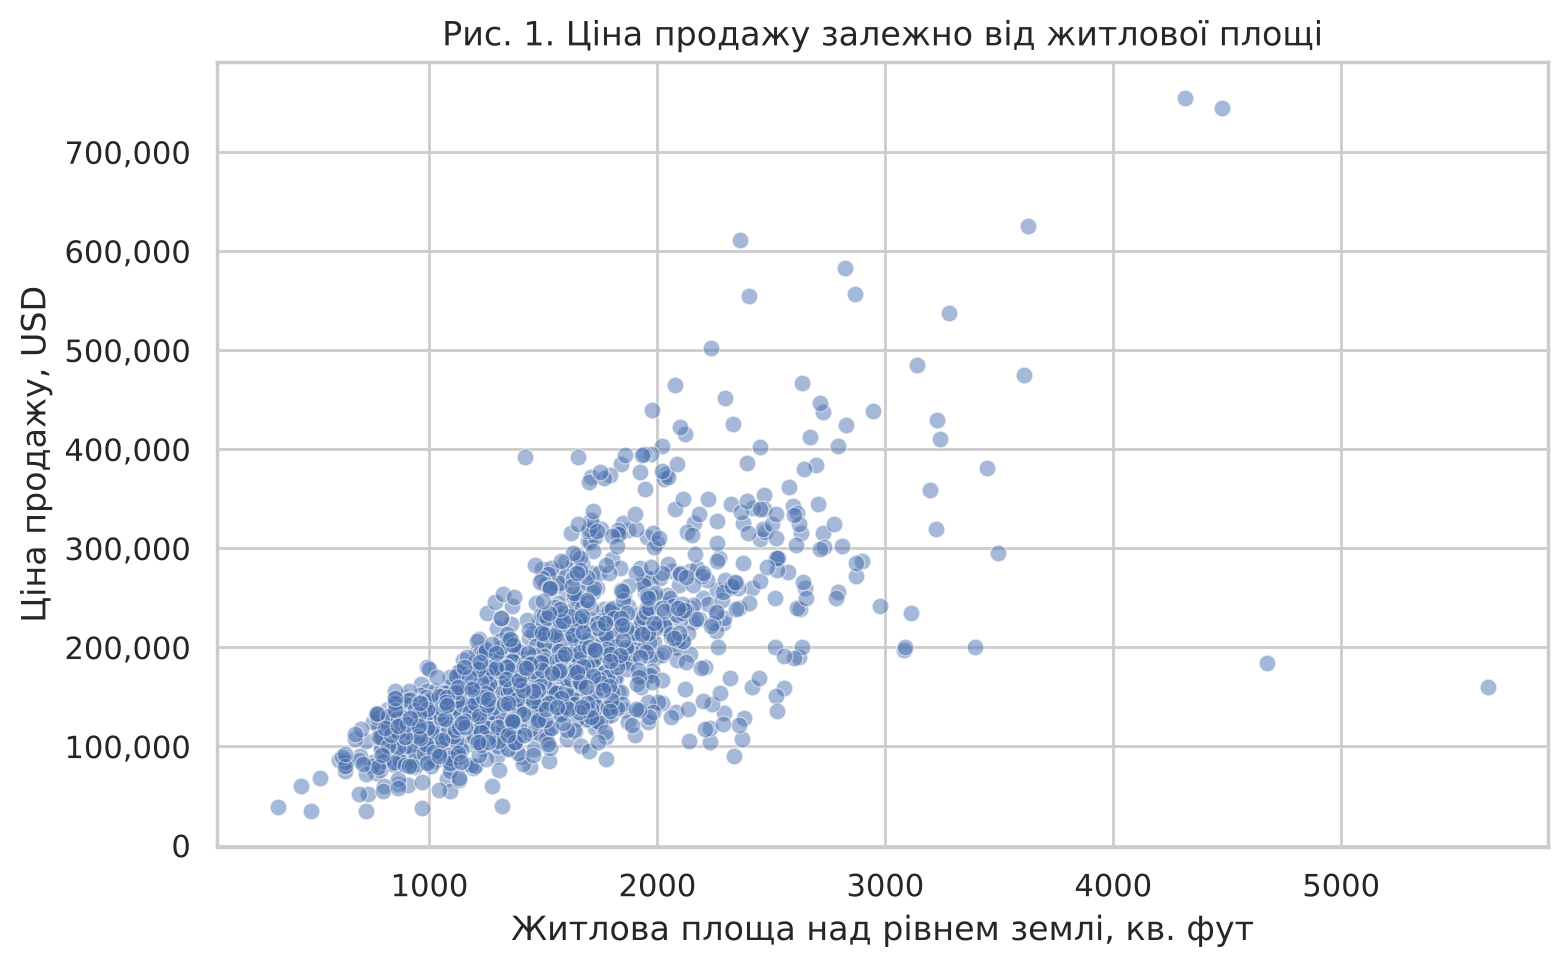

In [13]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=df, x="GrLivArea", y="SalePrice", alpha=0.5, ax=ax)
ax.set_title("Рис. 1. Ціна продажу залежно від житлової площі")
ax.set_xlabel("Житлова площа над рівнем землі, кв. фут")
ax.set_ylabel("Ціна продажу, USD")
ax.yaxis.set_major_formatter(lambda x, _: f"{x:,.0f}")
fig.tight_layout()
fig.savefig(FIG_DIR / "01_price_vs_area.png", dpi=150)
plt.show()

In [14]:
# Підозрілі угоди: дуже велика площа за дуже низькою ціною
suspicious = df[(df["GrLivArea"] > 4000)][["Id", "Neighborhood", "GrLivArea", "SalePrice", "SaleCondition"]]
suspicious

,Id,Neighborhood,GrLivArea,SalePrice,SaleCondition
523,524,Edwards,4676,184750,Partial
691,692,NoRidge,4316,755000,Normal
1182,1183,NoRidge,4476,745000,Abnorml
1298,1299,Edwards,5642,160000,Partial


**Висновок.** За правилом IQR у `SalePrice` 61 викид (4,2%), що природно для ринку нерухомості: дорогі будинки існують реально, тому їх не видаляємо. Окремо розглянуто 4 будинки з площею понад 4000 кв. фут. Два з них (`Id` 692 і 1183, район NoRidge) коштують понад \$740 000, що узгоджується з їхньою площею, тож це реальні дорогі продажі. Інші два (`Id` 524 і 1299, район Edwards) мають ціни \$184 750 і \$160 000 за площу 4676 і 5642 кв. фут, і в обох `SaleCondition = Partial`: будинок продано до завершення будівництва, тому ціна не відображає повну вартість. Саме ці дві угоди позначаємо прапорцем `IsAnomaly` і далі порівнюємо результати з ними та без них (питання 5), а не вилучаємо мовчки.

In [15]:
df["IsAnomaly"] = ((df["GrLivArea"] > 4000) & (df["SalePrice"] < 300000)).astype(int)
print("Позначено аномальних угод:", df["IsAnomaly"].sum())

Позначено аномальних угод: 2


### 4.5. Підсумок очищення і збереження

In [16]:
cleaning_report = pd.DataFrame({
    "Показник": [
        "Записів", "Ознак (було)", "Ознак (стало)", "Повних дублікатів",
        "Пропусків до очищення", "Пропусків після очищення", "Записів, позначених як аномалії",
    ],
    "Значення": [
        len(df), df_raw.shape[1], df.shape[1], int(dup_full),
        int(df_raw.isna().sum().sum()), int(df.isna().sum().sum()), int(df["IsAnomaly"].sum()),
    ],
})
cleaning_report

,Показник,Значення
0,Записів,1460
1,Ознак (було),81
2,Ознак (стало),84
3,Повних дублікатів,0
4,Пропусків до очищення,7829
5,Пропусків після очищення,81
6,"Записів, позначених як аномалії",2


In [17]:
df.to_csv(PROCESSED_PATH, index=False)
print("Збережено:", PROCESSED_PATH)

Збережено: ../data/processed/ames_clean.csv


## 5. Створення аналітичних ознак

Нові ознаки допомагають відповісти на дослідницькі питання 2–4.

| Ознака | Формула | Навіщо |
|---|---|---|
| `HouseAge` | `YrSold − YearBuilt` | вік будинку на момент продажу (питання 2) |
| `PricePerSqFt` | `SalePrice / GrLivArea` | ціна за кв. фут: порівнювати будинки різного розміру (питання 1, 2) |
| `TotalSF` | підвал + 1-й + 2-й поверхи | загальна площа будинку |
| `WasRemodeled` | `YearRemodAdd > YearBuilt` | чи був ремонт/добудова |
| `AgeGroup` | інтервали віку (`cut`) | категорії для порівняння груп |
| `SizeCategory` | квартилі `GrLivArea` (`qcut`) | категорії розміру: малий / середній / великий / дуже великий |

In [18]:
df["HouseAge"] = df["YrSold"] - df["YearBuilt"]
df["PricePerSqFt"] = df["SalePrice"] / df["GrLivArea"]
df["TotalSF"] = df["TotalBsmtSF"] + df["1stFlrSF"] + df["2ndFlrSF"]
df["WasRemodeled"] = (df["YearRemodAdd"] > df["YearBuilt"]).astype(int)

df["AgeGroup"] = pd.cut(
    df["HouseAge"], bins=[-1, 5, 20, 50, 200],
    labels=["Новий (до 5 р.)", "5–20 р.", "20–50 р.", "Старий (50+ р.)"],
)
df["SizeCategory"] = pd.qcut(
    df["GrLivArea"], q=4, labels=["Малий", "Середній", "Великий", "Дуже великий"],
)
df[["HouseAge", "PricePerSqFt", "TotalSF", "WasRemodeled", "AgeGroup", "SizeCategory"]].head()

,HouseAge,PricePerSqFt,TotalSF,WasRemodeled,AgeGroup,SizeCategory
0,5,121.93,2566,0,Новий (до 5 р.),Великий
1,31,143.82,2524,0,20–50 р.,Середній
2,7,125.14,2706,1,5–20 р.,Дуже великий
3,91,81.54,2473,1,Старий (50+ р.),Великий
4,8,113.74,3343,0,5–20 р.,Дуже великий


In [19]:
# Перевірка коректності: чи немає від'ємного віку (продаж до побудови)
print("Мінімальний вік:", df["HouseAge"].min(), "| записів з віком < 0:", (df["HouseAge"] < 0).sum())
print()
print(df["AgeGroup"].value_counts().sort_index())
print()
print(df["SizeCategory"].value_counts().sort_index())

Мінімальний вік: 0 | записів з віком < 0: 0

AgeGroup
Новий (до 5 р.)    310
5–20 р.            254
20–50 р.           457
Старий (50+ р.)    439
Name: count, dtype: int64

SizeCategory
Малий           365
Середній        366
Великий         364
Дуже великий    365
Name: count, dtype: int64


## 6. Описова статистика, групування й ранжування

### 6.1. Описова статистика ціни та ключових ознак

In [20]:
key_cols = ["SalePrice", "PricePerSqFt", "GrLivArea", "HouseAge", "OverallQual"]
stats = df[key_cols].agg(["count", "mean", "median", "std", "min", "max"]).T
stats["Q1"] = df[key_cols].quantile(0.25)
stats["Q3"] = df[key_cols].quantile(0.75)
stats["Асиметрія"] = df[key_cols].skew()
stats

,count,mean,median,std,min,max,Q1,Q3,Асиметрія
SalePrice,"1,460.00","180,921.20","163,000.00","79,442.50","34,900.00","755,000.00","129,975.00","214,000.00",1.88
PricePerSqFt,"1,460.00",120.57,120.10,31.39,28.36,276.25,99.82,138.70,0.38
GrLivArea,"1,460.00","1,515.46","1,464.00",525.48,334.00,"5,642.00","1,129.50","1,776.75",1.37
HouseAge,"1,460.00",36.55,35.00,30.25,0.00,136.00,8.00,54.00,0.61
OverallQual,"1,460.00",6.10,6.00,1.38,1.00,10.00,5.00,7.00,0.22


**Висновок.** Середня ціна продажу (\$180 921) вища за медіану (\$163 000), а асиметрія додатна (1,88). Це означає, що розподіл цін скошений вправо: невелика кількість дорогих будинків (максимум \$755 000) підтягує середнє вгору, тоді як половина будинків коштує менше \$163 000. Для опису типової ціни тому надійніша медіана. Ціна за кв. фут розподілена симетричніше (асиметрія 0,38), а її медіана становить \$120,10.

### 6.2. Ціна за районами (питання 1)

In [21]:
by_nbhd = (
    df.groupby("Neighborhood")
      .agg(Продажів=("Id", "count"),
           Середня_ціна=("SalePrice", "mean"),
           Медіанна_ціна=("SalePrice", "median"),
           Ціна_за_кв_фут=("PricePerSqFt", "median"))
      .round(0)
      .sort_values("Медіанна_ціна", ascending=False)
)
by_nbhd.head(10)

,Продажів,Середня_ціна,Медіанна_ціна,Ціна_за_кв_фут
Neighborhood,,,,
NridgHt,77,"316,271.00","315,000.00",158.00
NoRidge,41,"335,295.00","301,500.00",128.00
StoneBr,25,"310,499.00","278,000.00",158.00
Timber,38,"242,247.00","228,475.00",134.00
Somerst,86,"225,380.00","225,500.00",137.00
Veenker,11,"238,773.00","218,000.00",144.00
Crawfor,51,"210,625.00","200,624.00",116.00
ClearCr,28,"212,565.00","200,250.00",119.00
CollgCr,150,"197,966.00","197,200.00",135.00


In [22]:
# Ранжування: топ-5 найдорожчих і найдешевших районів за медіанною ціною
print("ТОП-5 найдорожчих:")
print(by_nbhd["Медіанна_ціна"].nlargest(5))
print("\nТОП-5 найдешевших:")
print(by_nbhd["Медіанна_ціна"].nsmallest(5))

ТОП-5 найдорожчих:
Neighborhood
NridgHt   315,000.00
NoRidge   301,500.00
StoneBr   278,000.00
Timber    228,475.00
Somerst   225,500.00
Name: Медіанна_ціна, dtype: float64

ТОП-5 найдешевших:
Neighborhood
MeadowV    88,000.00
IDOTRR    103,000.00
BrDale    106,000.00
OldTown   119,000.00
Edwards   121,750.00
Name: Медіанна_ціна, dtype: float64


In [23]:
# Ранг району та відношення до медіани по місту
by_nbhd["Ранг"] = by_nbhd["Медіанна_ціна"].rank(ascending=False).astype(int)
city_median = df["SalePrice"].median()
by_nbhd["Відхилення_від_міської_медіани_%"] = ((by_nbhd["Медіанна_ціна"] / city_median - 1) * 100).round(1)
by_nbhd[["Ранг", "Продажів", "Медіанна_ціна", "Відхилення_від_міської_медіани_%"]].head(8)

,Ранг,Продажів,Медіанна_ціна,Відхилення_від_міської_медіани_%
Neighborhood,,,,
NridgHt,1,77,"315,000.00",93.30
NoRidge,2,41,"301,500.00",85.00
StoneBr,3,25,"278,000.00",70.60
Timber,4,38,"228,475.00",40.20
Somerst,5,86,"225,500.00",38.30
Veenker,6,11,"218,000.00",33.70
Crawfor,7,51,"200,624.00",23.10
ClearCr,8,28,"200,250.00",22.90


**Висновок.** Найдорожчі райони за медіанною ціною: NridgHt (\$315 000, на 93% вище за міську медіану), NoRidge (\$301 500) і StoneBr (\$278 000). Найдешевший район — MeadowV (\$88 000), далі IDOTRR і BrDale. Списки за загальною ціною та за ціною кв. фута збігаються не повністю: NoRidge другий за ціною будинку, але його ціна за кв. фут (\$128) нижча, ніж у Somerst (\$137) чи CollgCr (\$135), бо там переважають великі будинки (медіанна площа 2418 кв. фут проти 1464 по місту). Медіани районів із малою кількістю продажів (Veenker — 11, Blmngtn — 17) менш надійні, ніж у районах із сотнею й більше продажів.

### 6.3. Ціна за умовами продажу, типом будинку та віком (питання 2, 4)

In [24]:
by_cond = (df.groupby("SaleCondition")
             .agg(Продажів=("Id", "count"), Медіанна_ціна=("SalePrice", "median"),
                  Ціна_за_кв_фут=("PricePerSqFt", "median"))
             .round(0).sort_values("Медіанна_ціна", ascending=False))
by_cond

,Продажів,Медіанна_ціна,Ціна_за_кв_фут
SaleCondition,,,
Partial,125,"244,600.00",149.00
Normal,1198,"160,000.00",119.00
Alloca,12,"148,145.00",83.00
Family,20,"140,500.00",104.00
Abnorml,101,"130,000.00",104.00
AdjLand,4,"104,000.00",91.00


In [25]:
by_bldg = (df.groupby("BldgType")
             .agg(Продажів=("Id", "count"), Медіанна_ціна=("SalePrice", "median"))
             .round(0).sort_values("Медіанна_ціна", ascending=False))
by_bldg

,Продажів,Медіанна_ціна
BldgType,,
TwnhsE,114,"172,200.00"
1Fam,1220,"167,900.00"
Twnhs,43,"137,500.00"
Duplex,52,"135,980.00"
2fmCon,31,"127,500.00"


In [26]:
by_age = (df.groupby("AgeGroup", observed=True)
            .agg(Продажів=("Id", "count"), Медіанна_ціна=("SalePrice", "median"),
                 Ціна_за_кв_фут=("PricePerSqFt", "median"))
            .round(0))
by_age

,Продажів,Медіанна_ціна,Ціна_за_кв_фут
AgeGroup,,,
Новий (до 5 р.),310,"225,500.00",143.00
5–20 р.,254,"212,500.00",125.00
20–50 р.,457,"147,000.00",121.00
Старий (50+ р.),439,"127,000.00",98.00


**Висновок.** Найдорожча група за умовами продажу — Partial (медіана \$244 600 проти \$160 000 у Normal): це будинки, продані до завершення будівництва, і 97,6% із них мають вік до 5 років. Найнижчі медіани мають Abnorml (\$130 000) і AdjLand (\$104 000), але групи з малою кількістю продажів (AdjLand — 4) не варто оцінювати надто впевнено. Ціна знижується зі збільшенням віку будинку: від \$225 500 у нових (до 5 років) до \$127 000 у будинків старших за 50 років. Те саме видно за ціною кв. фута (\$143 проти \$98), хоча між групами «5–20 років» (\$125) і «20–50 років» (\$121) різниця за цим показником невелика.

### 6.4. Вплив аномалій (питання 5)

In [27]:
with_anom = df["SalePrice"].agg(["mean", "median", "std"])
without_anom = df.loc[df["IsAnomaly"] == 0, "SalePrice"].agg(["mean", "median", "std"])
corr_with = df["GrLivArea"].corr(df["SalePrice"])
corr_without = df.loc[df["IsAnomaly"] == 0, "GrLivArea"].corr(df.loc[df["IsAnomaly"] == 0, "SalePrice"])

anom_effect = pd.DataFrame(
    {"З аномаліями": with_anom, "Без аномалій": without_anom}
)
anom_effect.loc["Кореляція GrLivArea–SalePrice"] = [corr_with, corr_without]
anom_effect.round(3)

,З аномаліями,Без аномалій
mean,"180,921.20","180,932.92"
median,"163,000.00","163,000.00"
std,"79,442.50","79,495.05"
Кореляція GrLivArea–SalePrice,0.71,0.73


**Висновок.** Після вилучення двох аномальних угод середня ціна майже не змінилася (\$180 921 → \$180 933), медіана лишилась \$163 000, стандартне відхилення змінилося приблизно на \$53. Проте кореляція між житловою площею та ціною зросла з 0,71 до 0,73. Обидва будинки мають площу понад 4 600 кв. фут за низької ціни, тож лежать далеко від загальної залежності й саме на кореляцію впливають найбільше. Оскільки це лише 2 записи з 1460 (0,1%), на описові показники вони майже не впливають. Їх залишено в наборі з позначкою `IsAnomaly`, але в оцінках залежності ціни від площі їх варто виключати.

In [28]:
df.to_csv(PROCESSED_PATH, index=False)
print("Оновлено:", PROCESSED_PATH, "| ознак:", df.shape[1])

Оновлено: ../data/processed/ames_clean.csv | ознак: 90


## 7. Об'єднання таблиць (`merge`) і зведені таблиці

Вихідний набір — одна широка таблиця, тому для демонстрації об'єднання даних її розбито на дві логічні частини (**характеристики будинку** та **інформація про продаж**) і додано два довідники, складені за `data_description.txt`: повні назви районів та групи типів житла. Це штучне розбиття (дані спершу були в одній таблиці), і про це чесно зазначено в записці.

| Таблиця | Вміст | Ключ |
|---|---|---|
| `houses` | характеристики будинку й ділянки | `Id` |
| `sales` | дата, умови й ціна продажу | `Id` |
| `neighborhoods` (довідник) | повна назва району | `Neighborhood` |
| `dwelling_types` (довідник) | опис типу житла й група | `MSSubClass` |

In [29]:
REF_DIR = Path("../data/raw/reference")
neighborhoods = pd.read_csv(REF_DIR / "neighborhoods.csv")
dwelling_types = pd.read_csv(REF_DIR / "dwelling_types.csv")

sales_cols = ["Id", "MoSold", "YrSold", "SaleDate", "SaleType", "SaleCondition",
              "SalePrice", "PricePerSqFt", "IsAnomaly"]
sales = df[sales_cols].copy()
houses = df.drop(columns=[c for c in sales_cols if c != "Id"]).copy()

print("houses:", houses.shape, "| sales:", sales.shape)
print("neighborhoods:", neighborhoods.shape, "| dwelling_types:", dwelling_types.shape)

houses: (1460, 82) | sales: (1460, 9)
neighborhoods: (25, 2) | dwelling_types: (16, 3)


In [30]:
# Об'єднання 1: будинки + продажі за ключем Id (один до одного)
merged = houses.merge(sales, on="Id", how="inner", validate="one_to_one")

# Об'єднання 2: + назви районів (багато до одного), left — щоб не втратити жодного продажу
merged = merged.merge(neighborhoods, on="Neighborhood", how="left", validate="many_to_one")

# Об'єднання 3: + групи типів житла (MSSubClass у df — категорія, у довіднику — число)
merged["MSSubClass"] = merged["MSSubClass"].astype(int)
merged = merged.merge(dwelling_types, on="MSSubClass", how="left", validate="many_to_one")

# Перевірки коректності: ні втрат, ні дублювання рядків, немає невідомих значень
print("Рядків: до =", len(df), "| після =", len(merged))
print("Невідомих районів:", merged["NeighborhoodName"].isna().sum())
print("Невідомих типів житла:", merged["DwellingGroup"].isna().sum())
print("Сума цін збігається:", merged["SalePrice"].sum() == df["SalePrice"].sum())

Рядків: до = 1460 | після = 1460
Невідомих районів: 0
Невідомих типів житла: 0
Сума цін збігається: True


**Висновок.** Усі три об'єднання виконано без втрат і дублювання: кількість записів лишилась 1460, ціни збігаються з вихідними, для кожного району та типу житла знайдено відповідність. Параметр `validate` захищає від випадкового розмноження рядків, а `how="left"` гарантує, що жоден продаж не зникне, якщо в довіднику бракуватиме значення. Об'єднану таблицю `merged` використовуємо далі.

### 7.1. Зведені таблиці

In [31]:
# Зведена 1: медіанна ціна за віком і розміром будинку
pivot_age_size = merged.pivot_table(
    index="AgeGroup", columns="SizeCategory", values="SalePrice",
    aggfunc="median", observed=True,
).round(0)
pivot_age_size

SizeCategory,Малий,Середній,Великий,Дуже великий
AgeGroup,,,,
Новий (до 5 р.),"148,000.00","185,850.00","231,000.00","315,000.00"
5–20 р.,"143,000.00","179,000.00","194,500.00","241,500.00"
20–50 р.,"129,950.00","152,000.00","169,500.00","200,000.00"
Старий (50+ р.),"107,900.00","125,500.00","143,000.00","173,500.00"


In [32]:
# Зведена 2: кількість продажів за роками та умовами продажу
pd.crosstab(merged["YrSold"], merged["SaleCondition"], margins=True, margins_name="Разом")

SaleCondition,Abnorml,AdjLand,Alloca,Family,Normal,Partial,Разом
YrSold,,,,,,,
2006,33,2,1,8,227,43,314
2007,13,1,3,7,265,40,329
2008,21,1,2,0,264,16,304
2009,23,0,5,3,288,19,338
2010,11,0,1,2,154,7,175
Разом,101,4,12,20,1198,125,1460


In [33]:
# Зведена 3: кількість і медіанна ціна за групами типів житла
pivot_dwelling = merged.pivot_table(
    index="DwellingGroup", values="SalePrice", aggfunc=["count", "median"],
).round(0)
pivot_dwelling.columns = ["Продажів", "Медіанна_ціна"]
pivot_dwelling.sort_values("Медіанна_ціна", ascending=False)

,Продажів,Медіанна_ціна
DwellingGroup,,
2 поверхи,359,"207,500.00"
PUD (плановий комплекс),160,"164,250.00"
"2,5 поверха",16,"163,500.00"
Спліт/багаторівневий,78,"159,975.00"
1 поверх,609,"152,000.00"
Дуплекс,82,"134,450.00"
"1,5 поверха",156,"130,750.00"


**Висновок.** Зведена таблиця показує два незалежні ефекти. За однакового розміру нові будинки дорожчі за старі: у категорії «Дуже великий» медіана падає від 315 000 до 173 500 USD зі старінням, у категорії «Малий» — від 148 000 до 107 900 USD. За однакового віку більші будинки дорожчі: серед нових медіана зростає від 148 000 до 315 000 USD (у 2,1 раза), серед старих — від 107 900 до 173 500 USD (у 1,6 раза). Отже, вік і розмір потрібно враховувати разом. Таблиця за роками показує, що частка продажів `Partial` різко впала після 2007 року (43 і 40 продажів у 2006–2007 роках проти 16 і 19 у 2008–2009), тобто продажів нових будинків на етапі будівництва стало помітно менше. За групами типів житла найдорожчі двоповерхові будинки (медіана 207 500 USD), а найпоширеніші одноповерхові (609 продажів, 152 000 USD).

## 8. Аналіз взаємозв'язків (кореляції)

Кореляція Пірсона вимірює **лінійний** зв'язок між числовими ознаками (від −1 до 1). Високе значення не доводить, що одна ознака є причиною іншої: наприклад, площа й якість можуть зростати разом через розмір бюджету покупця.

In [34]:
# PricePerSqFt виключаємо: вона обчислена з самої ціни, тож кореляція була б штучною
numeric = merged.select_dtypes(include="number").drop(columns=["Id", "MSSubClass", "IsAnomaly", "PricePerSqFt"])
corr_price = numeric.corr()["SalePrice"].drop("SalePrice").sort_values(key=abs, ascending=False)
print("Топ-10 ознак за модулем кореляції з ціною:")
corr_price.head(10).round(3)

Топ-10 ознак за модулем кореляції з ціною:


OverallQual     0.79
TotalSF         0.78
GrLivArea       0.71
GarageCars      0.64
GarageArea      0.62
TotalBsmtSF     0.61
1stFlrSF        0.61
FullBath        0.56
TotRmsAbvGrd    0.53
HouseAge       -0.52
Name: SalePrice, dtype: float64

In [35]:
# Порівняння Пірсона зі Спірменом (рангова кореляція, стійка до викидів)
pairs = ["OverallQual", "GrLivArea", "TotalSF", "GarageCars", "HouseAge"]
comparison = pd.DataFrame({
    "Пірсон": [merged[c].corr(merged["SalePrice"]) for c in pairs],
    "Спірмен": [merged[c].corr(merged["SalePrice"], method="spearman") for c in pairs],
}, index=pairs).round(3)
comparison

,Пірсон,Спірмен
OverallQual,0.79,0.81
GrLivArea,0.71,0.73
TotalSF,0.78,0.82
GarageCars,0.64,0.69
HouseAge,-0.52,-0.65


**Висновок.** З ціною найсильніше пов'язані загальна якість `OverallQual` (0,79), загальна площа `TotalSF` (0,78) і житлова площа `GrLivArea` (0,71). Вік будинку має від'ємну кореляцію (−0,52): чим старіший будинок, тим нижча ціна. Кореляція Спірмена для віку (−0,65) за модулем більша за кореляцію Пірсона, тобто зв'язок монотонний, але не суворо лінійний. Високі значення не доводять причинності: більші будинки зазвичай мають кращу якість і більше кімнат одночасно. Ознаки `TotalSF`, `GrLivArea`, `GarageCars` і `GarageArea` пов'язані між собою ще сильніше (0,87–0,88), тому дублюють інформацію одна одної.

## 9. Аналіз динаміки в часі (питання 3)

Дані охоплюють січень 2006 – липень 2010. **2010 рік неповний** (лише 7 місяців), тому порівнювати кількість продажів за роками треба обережно.

In [36]:
yearly = (merged.groupby("YrSold")
            .agg(Продажів=("Id", "count"), Медіанна_ціна=("SalePrice", "median"),
                 Ціна_за_кв_фут=("PricePerSqFt", "median"))
            .round(0))
yearly["Зміна_медіани_до_попер_р_%"] = (yearly["Медіанна_ціна"].pct_change() * 100).round(1)
yearly

,Продажів,Медіанна_ціна,Ціна_за_кв_фут,Зміна_медіани_до_попер_р_%
YrSold,,,,
2006,314,"163,995.00",121.00,NaN
2007,329,"167,000.00",121.00,1.80
2008,304,"164,000.00",120.00,-1.80
2009,338,"162,000.00",118.00,-1.20
2010,175,"155,000.00",121.00,-4.30


In [37]:
# Помісячна динаміка + ковзне середнє за 3 місяці
monthly = (merged.groupby("SaleDate")
             .agg(Продажів=("Id", "count"), Медіанна_ціна=("SalePrice", "median"))
             .sort_index())
monthly["Медіана_ковзна_3м"] = monthly["Медіанна_ціна"].rolling(3, center=True).mean()
monthly.head(6)

,Продажів,Медіанна_ціна,Медіана_ковзна_3м
SaleDate,,,
2006-01-01,10,"176,700.00",NaN
2006-02-01,9,"192,500.00","177,366.67"
2006-03-01,25,"162,900.00","166,883.33"
2006-04-01,27,"145,250.00","155,033.33"
2006-05-01,38,"156,950.00","151,133.33"
2006-06-01,48,"151,200.00","156,050.00"


In [38]:
# Сезонність: кількість продажів за календарними місяцями (без неповного 2010)
seasonal = (merged[merged["YrSold"] < 2010]
              .groupby("MoSold")
              .agg(Продажів=("Id", "count"), Медіанна_ціна=("SalePrice", "median")))
seasonal.T

MoSold,1,2,3,4,5,6,7,8,9,10,11,12
Продажів,48.00,37.00,85.00,102.00,156.00,217.00,228.00,122.00,63.00,89.00,79.00,59.00
Медіанна_ціна,"147,000.00","173,500.00","167,000.00","143,826.00","154,950.00","162,900.00","167,500.00","174,450.00","185,900.00","159,000.00","173,000.00","178,000.00"


**Висновок.** Медіанна ціна за роками майже не змінювалась: 163 995 USD у 2006 році, 167 000 у 2007, 164 000 у 2008 і 162 000 у 2009. Помітне зниження до 155 000 USD (−4,3%) припадає на 2010 рік, але він охоплює лише січень–липень, тому порівняння неповне. Ціна за кв. фут трималась на рівні 118–121 USD. Різкого обвалу ринку, про який можна було б очікувати в період кризи 2008–2009 років, у цих даних для міста Еймс не видно; змінилась радше структура продажів (менше нових будинків, див. розділ 7.1). Сильніше виражена сезонність: у червні й липні (2006–2009) відбулось 217 і 228 продажів, а в лютому лише 37. Помісячні медіани нестабільні, бо базуються на невеликій кількості угод (від 6 до 67 на місяць), тому для висновків про тренд надійніше ковзне середнє й річні дані.

## 10. Візуалізація результатів

Усі графіки зберігаються у `results/figures/`. Рис. 1 (залежність ціни від площі) наведено в розділі 4.4.

### Рис. 2. Розподіл цін продажу

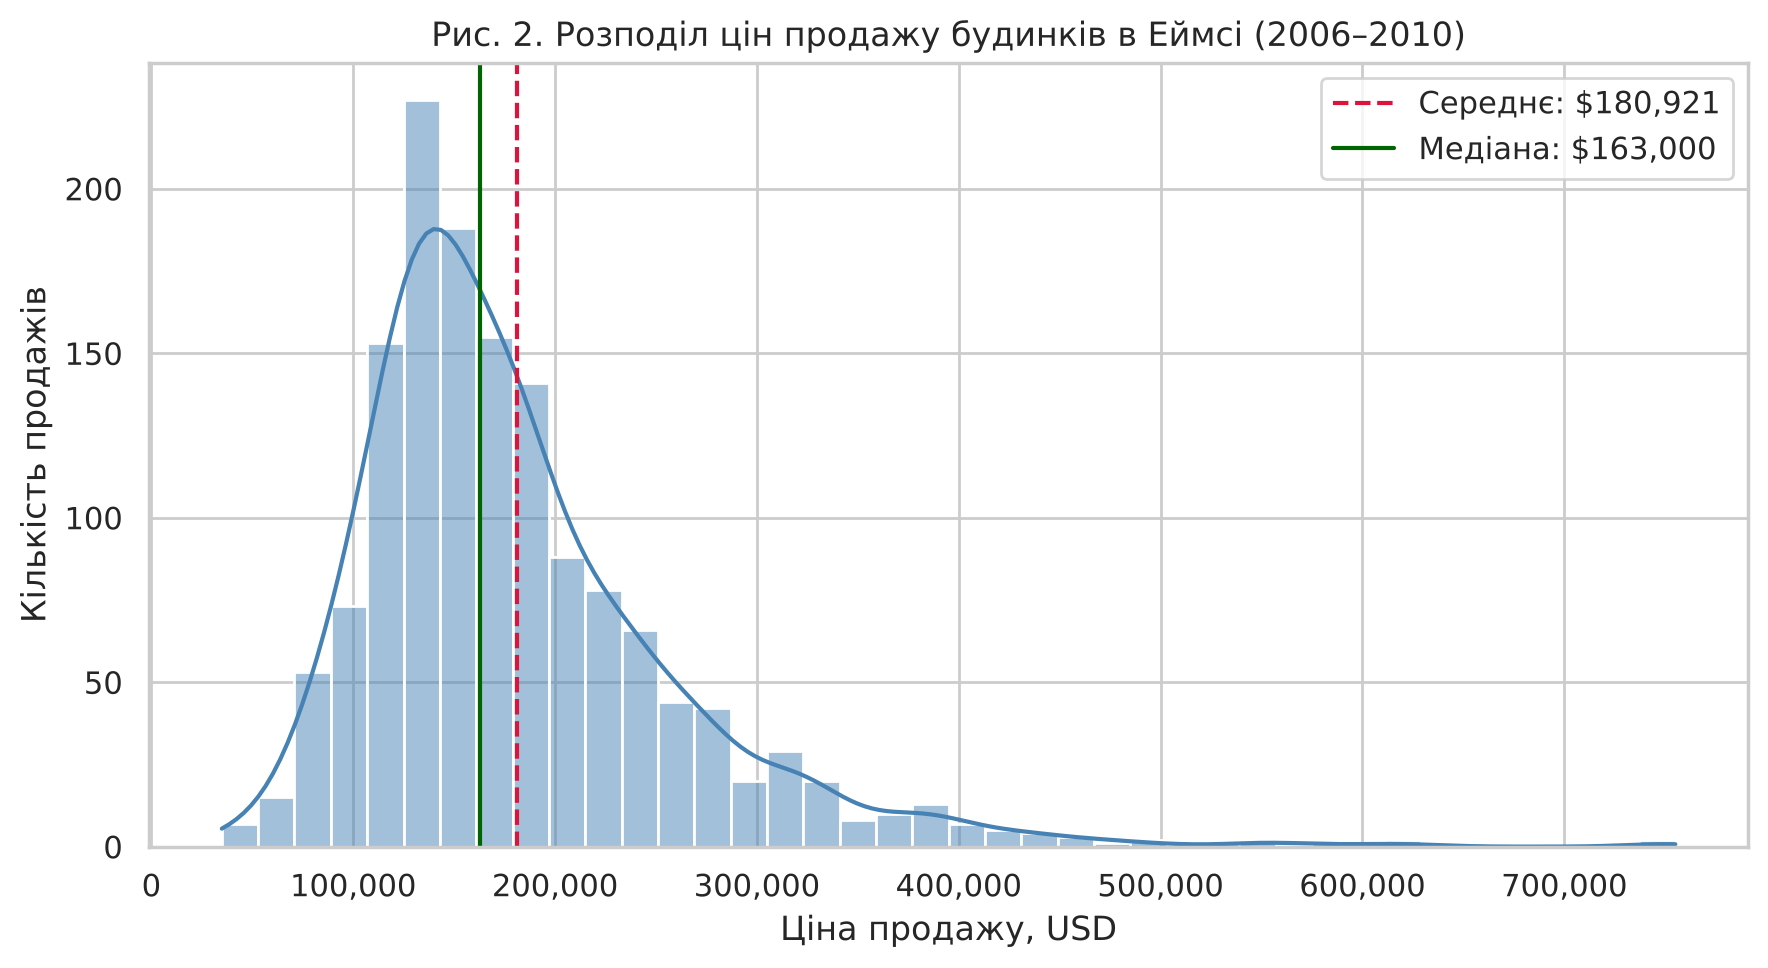

In [39]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(merged["SalePrice"], bins=40, kde=True, color="steelblue", ax=ax)
ax.axvline(merged["SalePrice"].mean(), color="crimson", linestyle="--", label=f"Середнє: \\${merged['SalePrice'].mean():,.0f}")
ax.axvline(merged["SalePrice"].median(), color="darkgreen", linestyle="-", label=f"Медіана: \\${merged['SalePrice'].median():,.0f}")
ax.set_title("Рис. 2. Розподіл цін продажу будинків в Еймсі (2006–2010)")
ax.set_xlabel("Ціна продажу, USD")
ax.set_ylabel("Кількість продажів")
ax.xaxis.set_major_formatter(lambda x, _: f"{x:,.0f}")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "02_price_distribution.png", dpi=150)
plt.show()

**Висновок.** Розподіл цін асиметричний вправо: більшість будинків коштує приблизно 100 000–200 000 USD, а «хвіст» тягнеться до 755 000 USD. Середнє (180 921 USD) лежить правіше за медіану (163 000 USD), що підтверджує вплив дорогих будинків. Тому для опису типової ціни використовуємо медіану, а при моделюванні варто розглянути логарифмування ціни.

### Рис. 3. Медіанна ціна за районами

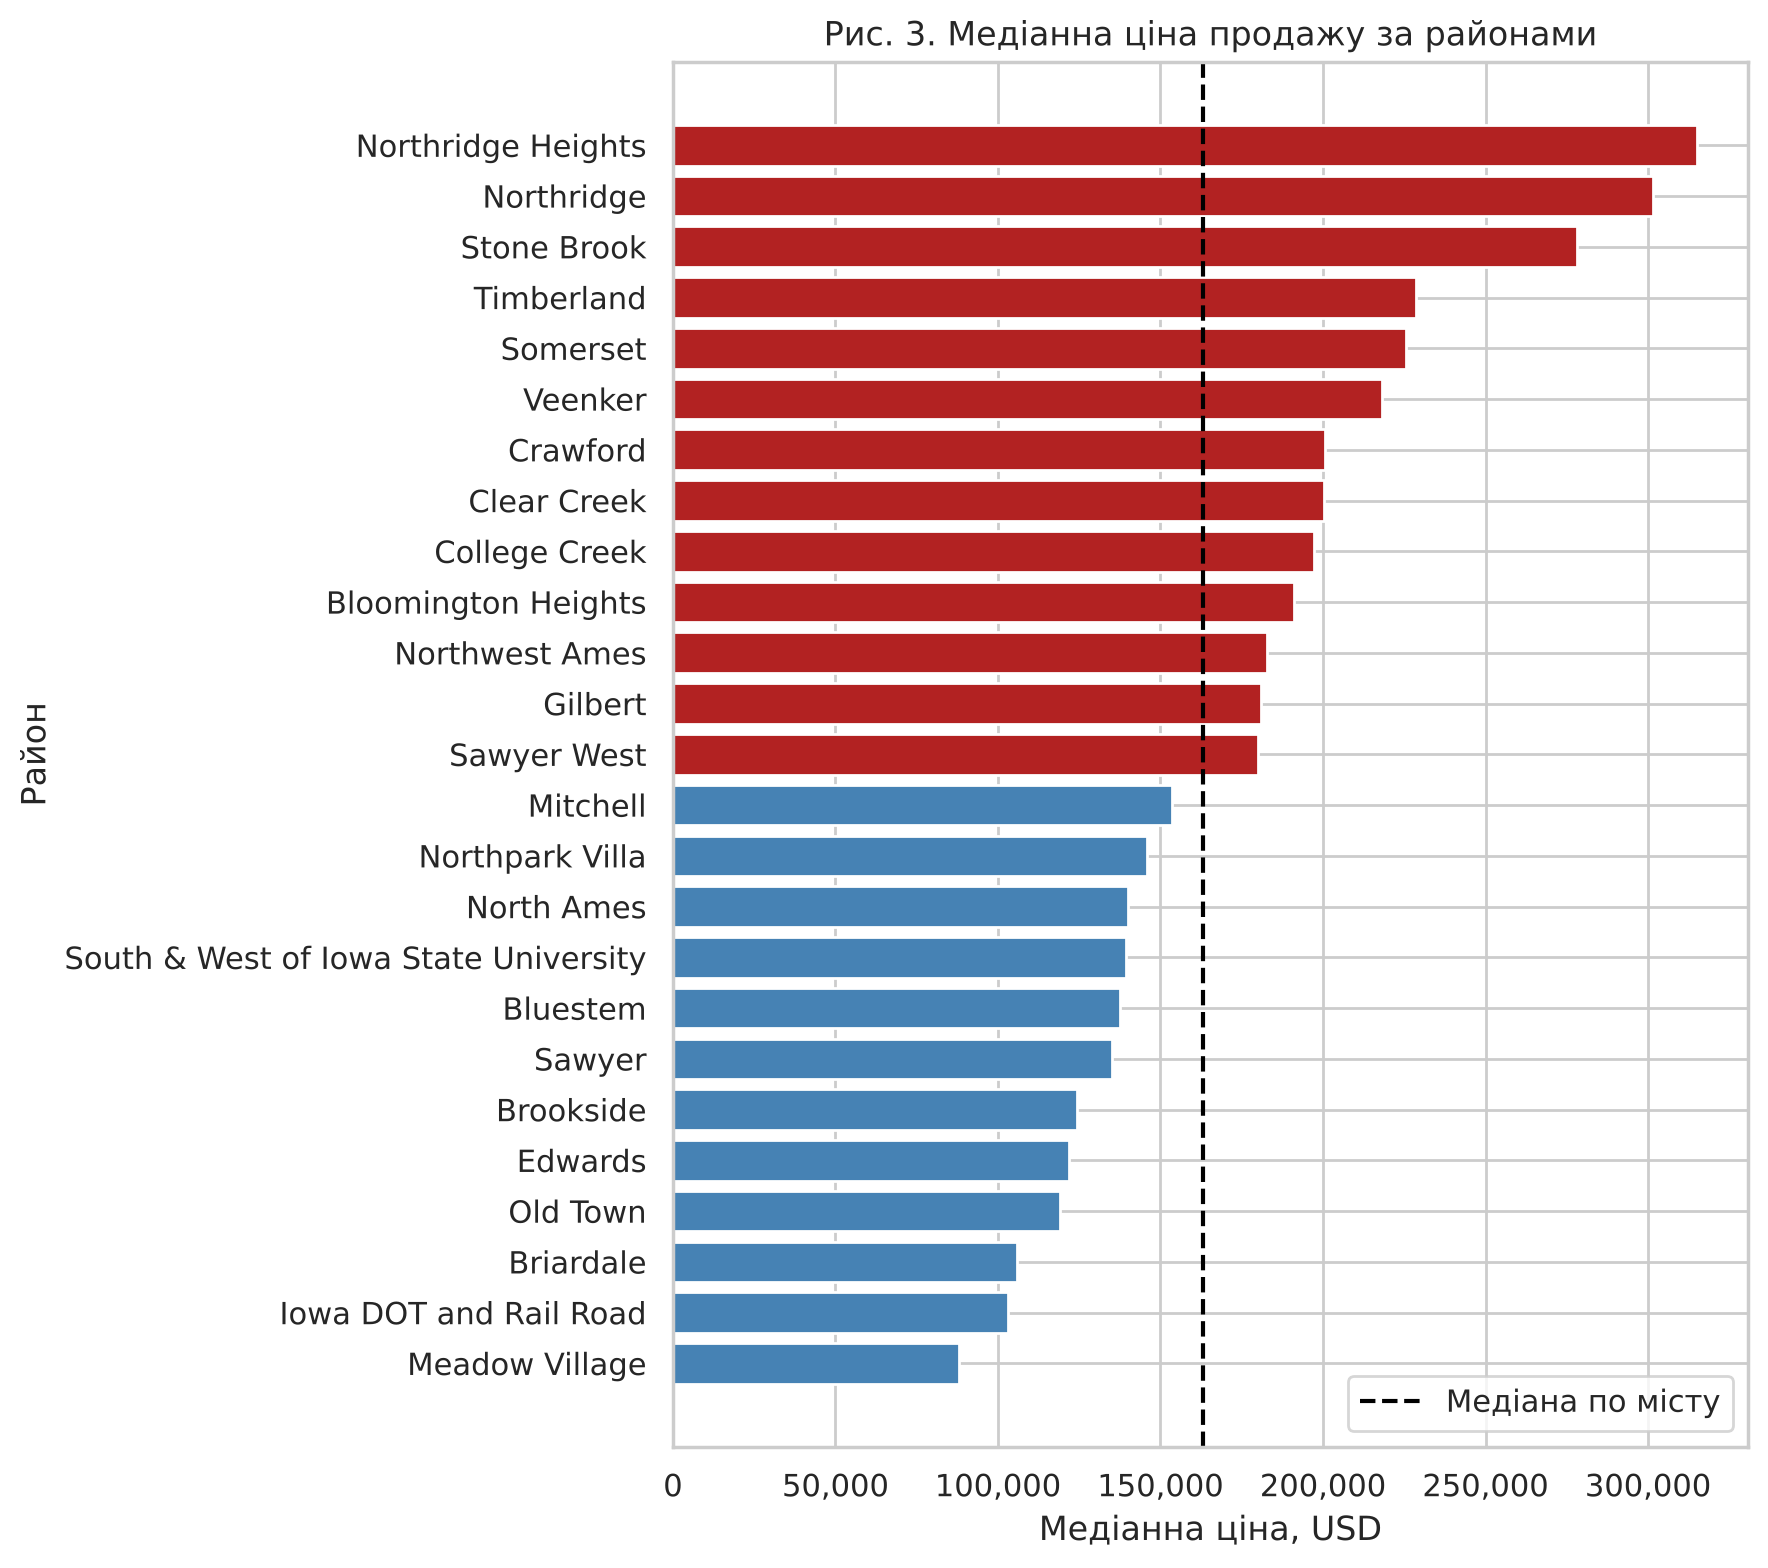

In [40]:
nb_med = merged.groupby("NeighborhoodName")["SalePrice"].median().sort_values()
fig, ax = plt.subplots(figsize=(9, 8))
colors = ["firebrick" if v > merged["SalePrice"].median() else "steelblue" for v in nb_med]
ax.barh(nb_med.index, nb_med.values, color=colors)
ax.axvline(merged["SalePrice"].median(), color="black", linestyle="--", label="Медіана по місту")
ax.set_title("Рис. 3. Медіанна ціна продажу за районами")
ax.set_xlabel("Медіанна ціна, USD")
ax.set_ylabel("Район")
ax.xaxis.set_major_formatter(lambda x, _: f"{x:,.0f}")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIG_DIR / "03_median_price_by_neighborhood.png", dpi=150)
plt.show()

**Висновок.** Із 25 районів 13 мають медіанну ціну вищу за міську. Найдорожчі — Northridge Heights (315 000 USD) і Northridge (301 500 USD), найдешевші — Meadow Village (88 000 USD) та Iowa DOT and Rail Road (103 000 USD). Розрив між найдорожчим і найдешевшим районом становить понад 3,5 раза, тобто район є одним із найсильніших чинників ціни. Для районів із малою кількістю продажів (див. розділ 6.2) медіана менш надійна.

### Рис. 4. Ціна залежно від віку будинку

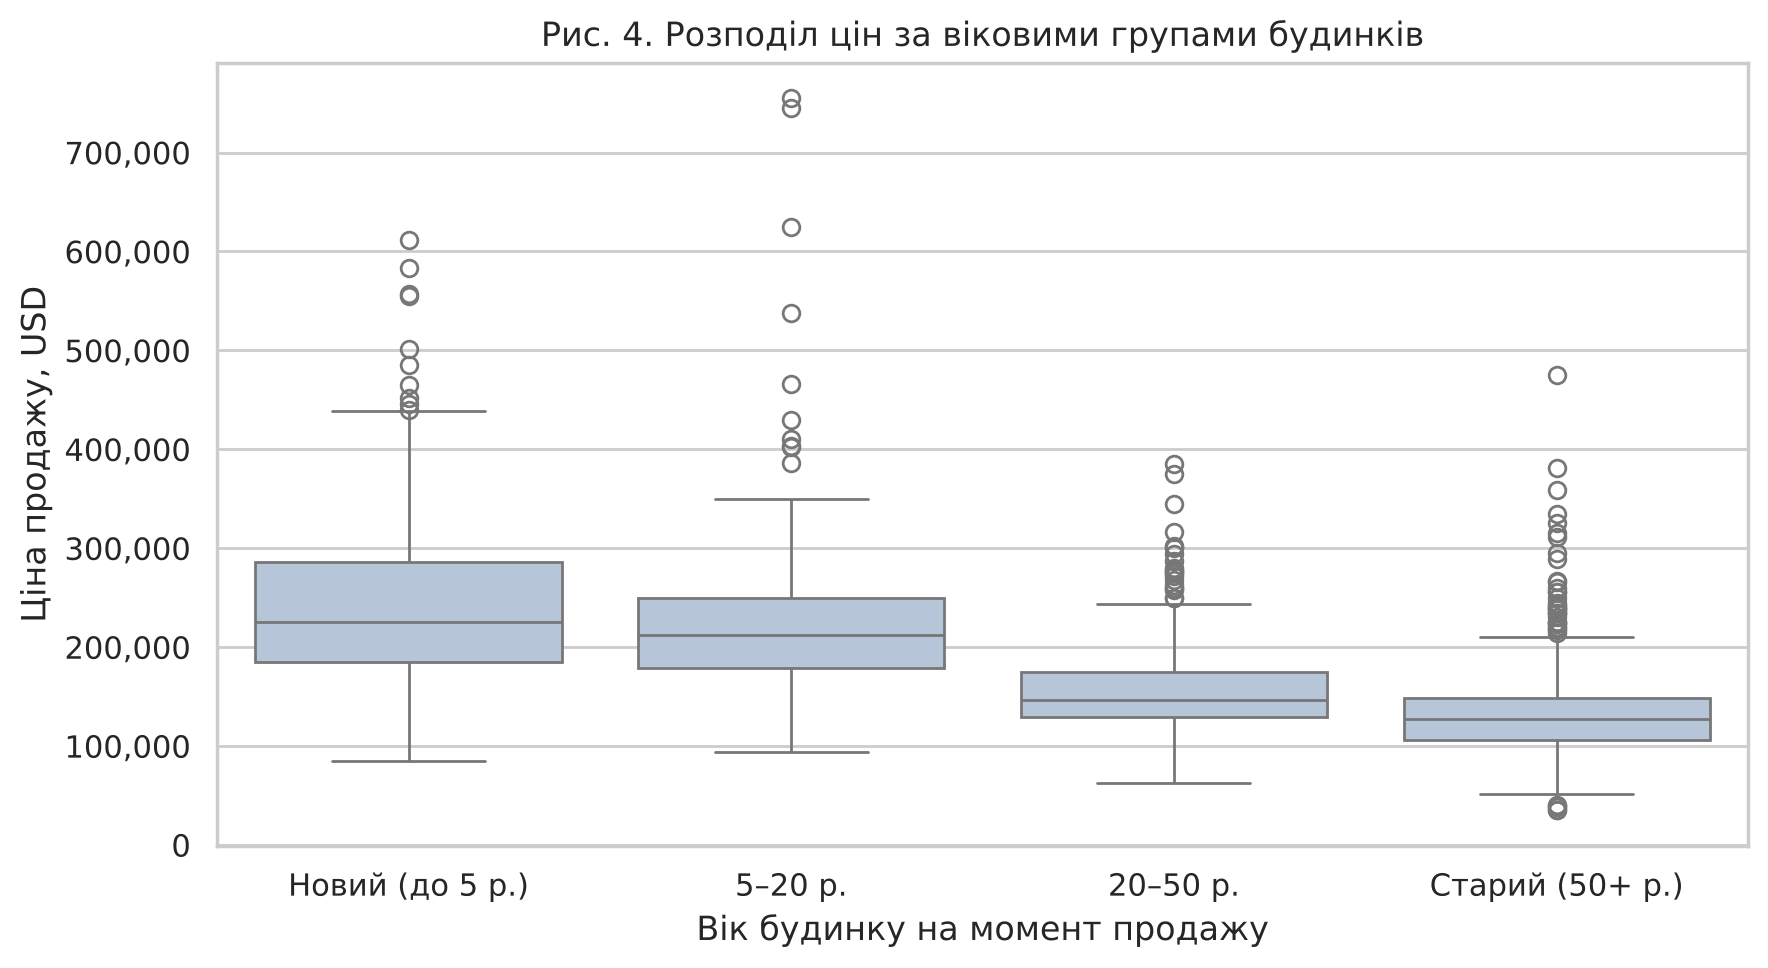

In [41]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=merged, x="AgeGroup", y="SalePrice", color="lightsteelblue", ax=ax)
ax.set_title("Рис. 4. Розподіл цін за віковими групами будинків")
ax.set_xlabel("Вік будинку на момент продажу")
ax.set_ylabel("Ціна продажу, USD")
ax.yaxis.set_major_formatter(lambda x, _: f"{x:,.0f}")
fig.tight_layout()
fig.savefig(FIG_DIR / "04_price_by_age_group.png", dpi=150)
plt.show()

**Висновок.** Медіана ціни зменшується зі збільшенням віку будинку: найвища в групі «до 5 років», найнижча в групі «50+ років». Розкид цін також різний: у нових будинків міжквартильний розмах найбільший (близько 101 800 USD), у найстаріших найменший (близько 42 400 USD). Тобто нові будинки сильно різняться за ціною (від бюджетних до елітних), а старі коштують більш однорідно й дешево. У всіх групах є викиди вгору, що відповідає дорогим окремим об'єктам.

### Рис. 5. Ціна залежно від загальної якості будинку

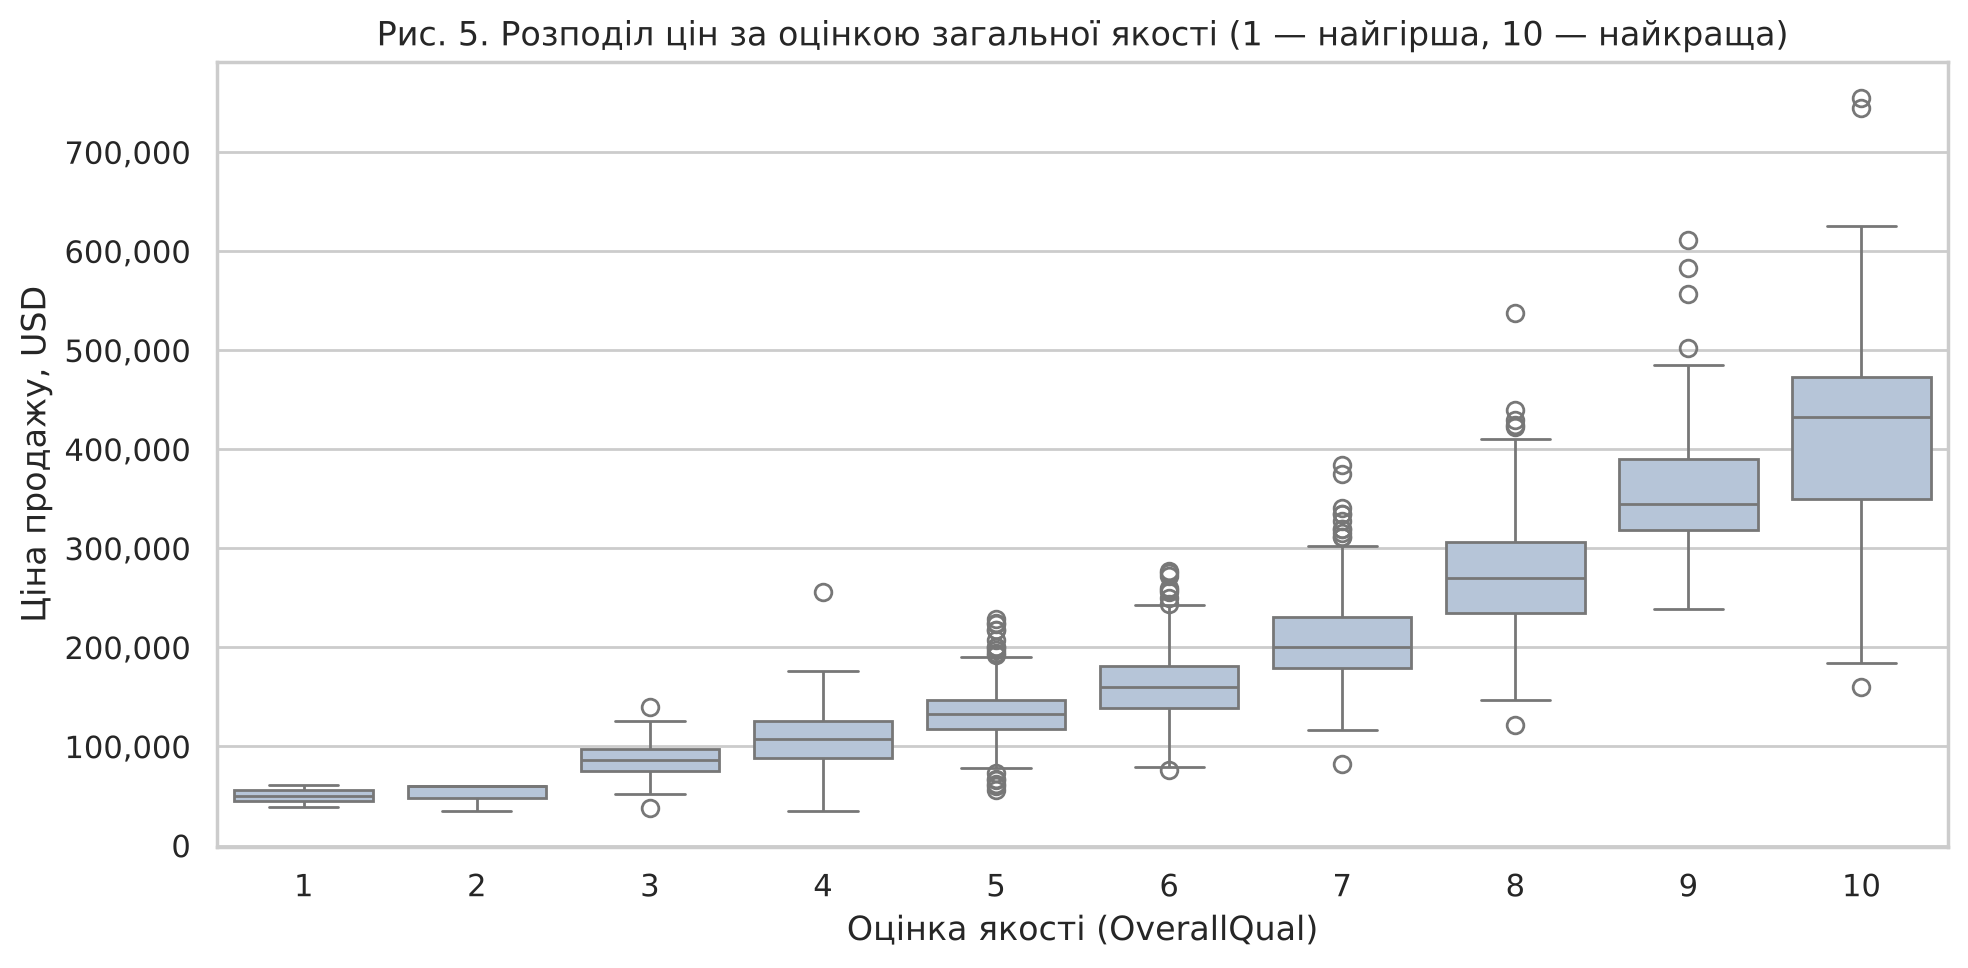

In [42]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=merged, x="OverallQual", y="SalePrice", color="lightsteelblue", ax=ax)
ax.set_title("Рис. 5. Розподіл цін за оцінкою загальної якості (1 — найгірша, 10 — найкраща)")
ax.set_xlabel("Оцінка якості (OverallQual)")
ax.set_ylabel("Ціна продажу, USD")
ax.yaxis.set_major_formatter(lambda x, _: f"{x:,.0f}")
fig.tight_layout()
fig.savefig(FIG_DIR / "05_price_by_quality.png", dpi=150)
plt.show()

**Висновок.** Ціна стабільно зростає з оцінкою якості: медіана від 133 000 USD при оцінці 5 до 200 141 USD при оцінці 7 і 432 390 USD при оцінці 10. Зростання прискорюється на високих оцінках: кожен крок після 7-ї додає приблизно 70 000–87 000 USD. Три чверті продажів (74,7%) припадає на оцінки 5–7, а оцінки 1–2 представлені лише 5 будинками, тому їхні медіани ненадійні.

### Рис. 6. Теплова карта кореляцій

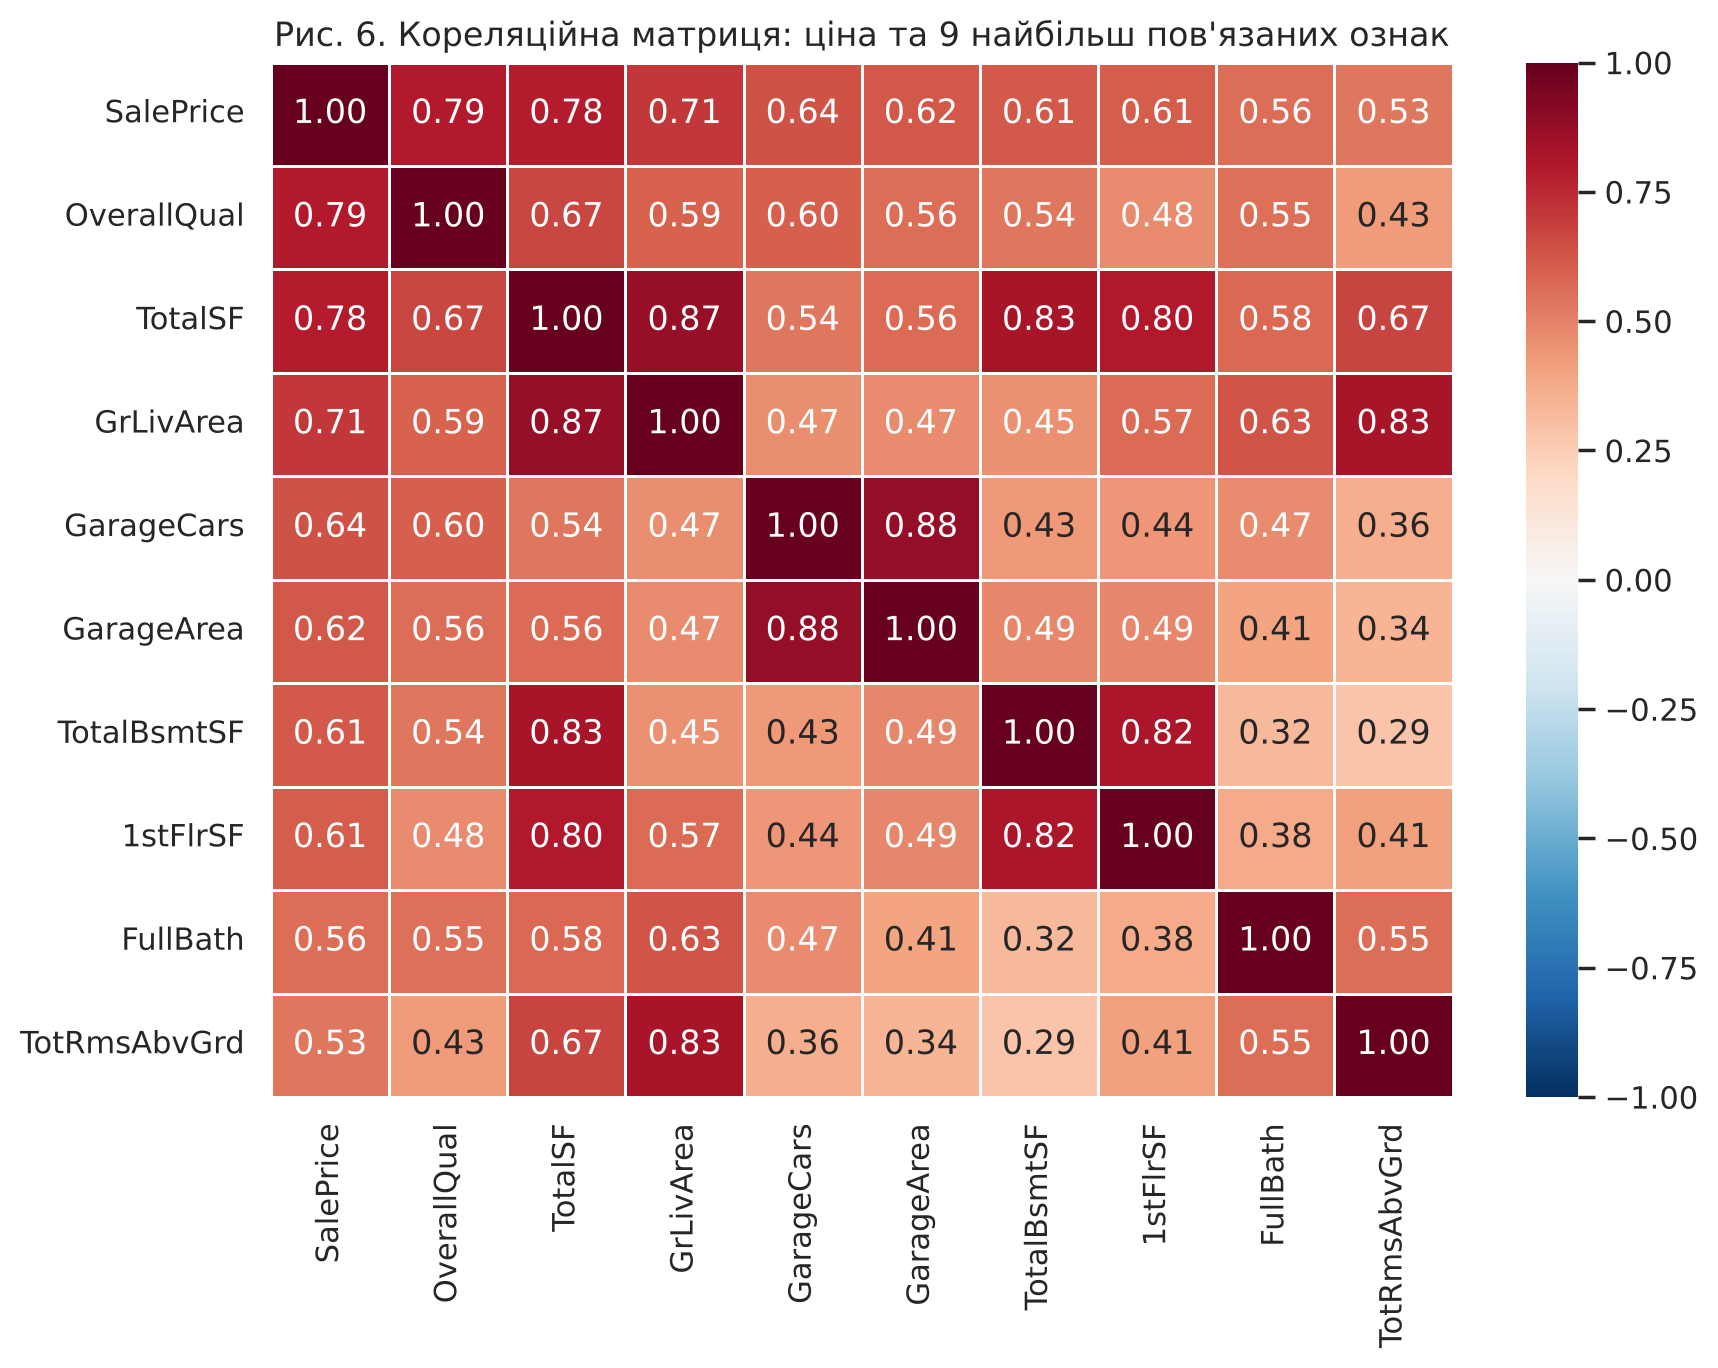

In [43]:
top_cols = ["SalePrice"] + list(corr_price.head(9).index)
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(merged[top_cols].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, linewidths=0.5, ax=ax)
ax.set_title("Рис. 6. Кореляційна матриця: ціна та 9 найбільш пов'язаних ознак")
fig.tight_layout()
fig.savefig(FIG_DIR / "06_correlation_heatmap.png", dpi=150)
plt.show()

**Висновок.** З ціною найсильніше пов'язані `OverallQual` (0,79) і `TotalSF` (0,78). Теплова карта також показує мультиколінеарність: `GarageCars` і `GarageArea` (0,88), `TotalSF` і `GrLivArea` (0,87), `GrLivArea` і `TotRmsAbvGrd` (0,83) майже дублюють одна одну. У подальшому моделюванні з кожної такої пари достатньо однієї ознаки. Кореляція вимірює лише лінійний зв'язок і не доводить причинності.

### Рис. 7. Динаміка ринку в часі

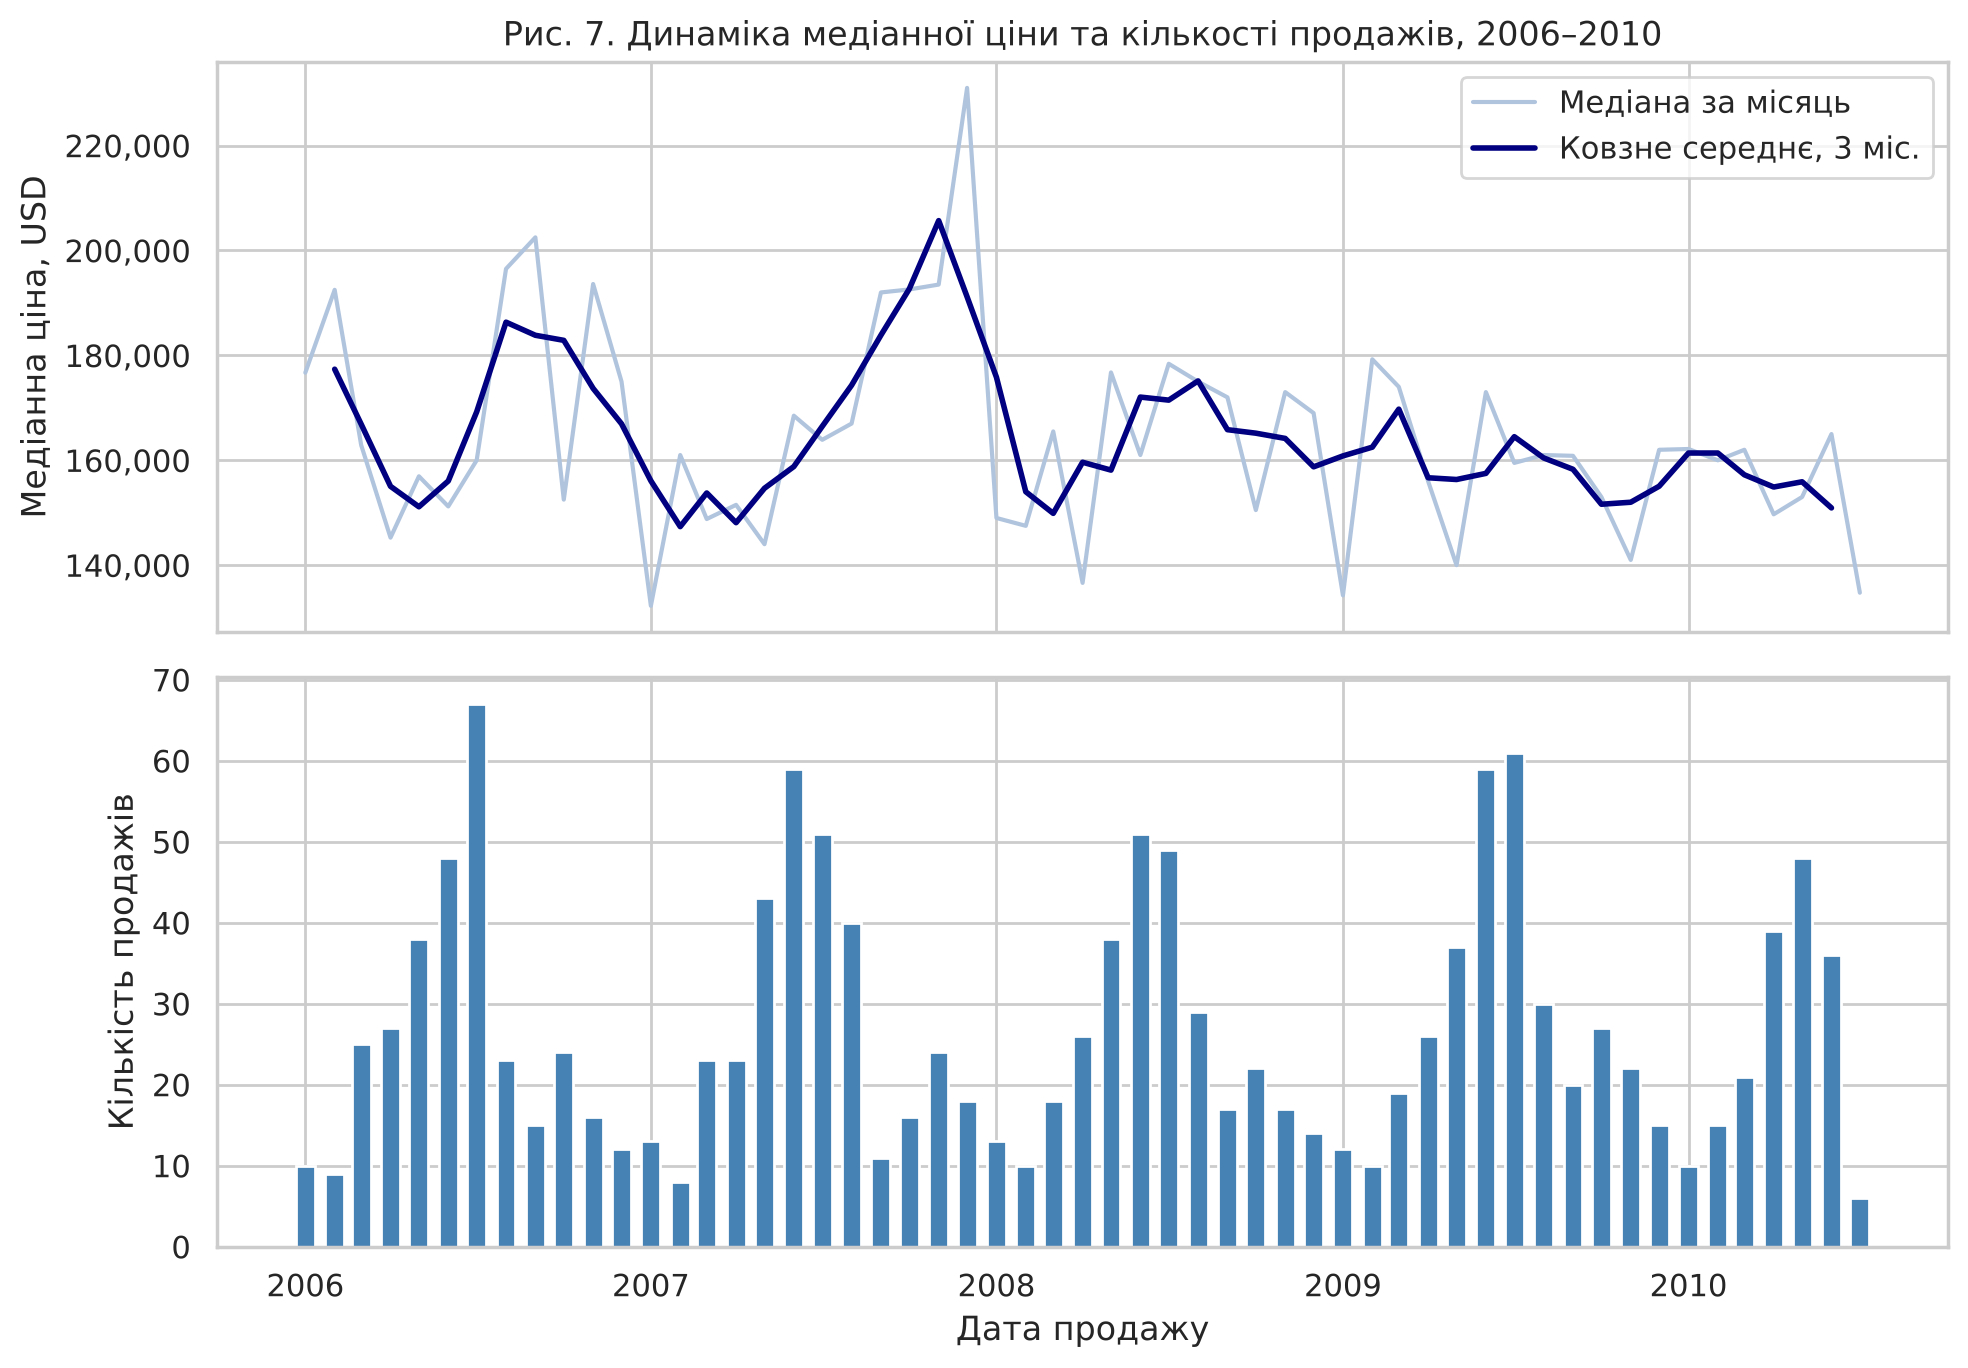

In [44]:
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
axes[0].plot(monthly.index, monthly["Медіанна_ціна"], color="lightsteelblue", label="Медіана за місяць")
axes[0].plot(monthly.index, monthly["Медіана_ковзна_3м"], color="navy", linewidth=2, label="Ковзне середнє, 3 міс.")
axes[0].set_title("Рис. 7. Динаміка медіанної ціни та кількості продажів, 2006–2010")
axes[0].set_ylabel("Медіанна ціна, USD")
axes[0].yaxis.set_major_formatter(lambda x, _: f"{x:,.0f}")
axes[0].legend()
axes[1].bar(monthly.index, monthly["Продажів"], width=20, color="steelblue")
axes[1].set_ylabel("Кількість продажів")
axes[1].set_xlabel("Дата продажу")
fig.tight_layout()
fig.savefig(FIG_DIR / "07_market_dynamics.png", dpi=150)
plt.show()

**Висновок.** Кількість продажів має чітку сезонність: щороку пік припадає на травень–липень, а мінімум на зимові місяці. Ковзне середнє медіанної ціни коливається в діапазоні приблизно 147 000–206 000 USD без стійкого тренду, із піком наприкінці 2007 року (грудень 2007: медіана 231 000 USD, але лише 18 продажів) і поступовим зниженням у 2008–2010 роках. Останній місяць (липень 2010) містить лише 6 продажів, тому його значення не слід інтерпретувати.

### Рис. 8. Теплова карта зведеної таблиці: ціна за віком і розміром

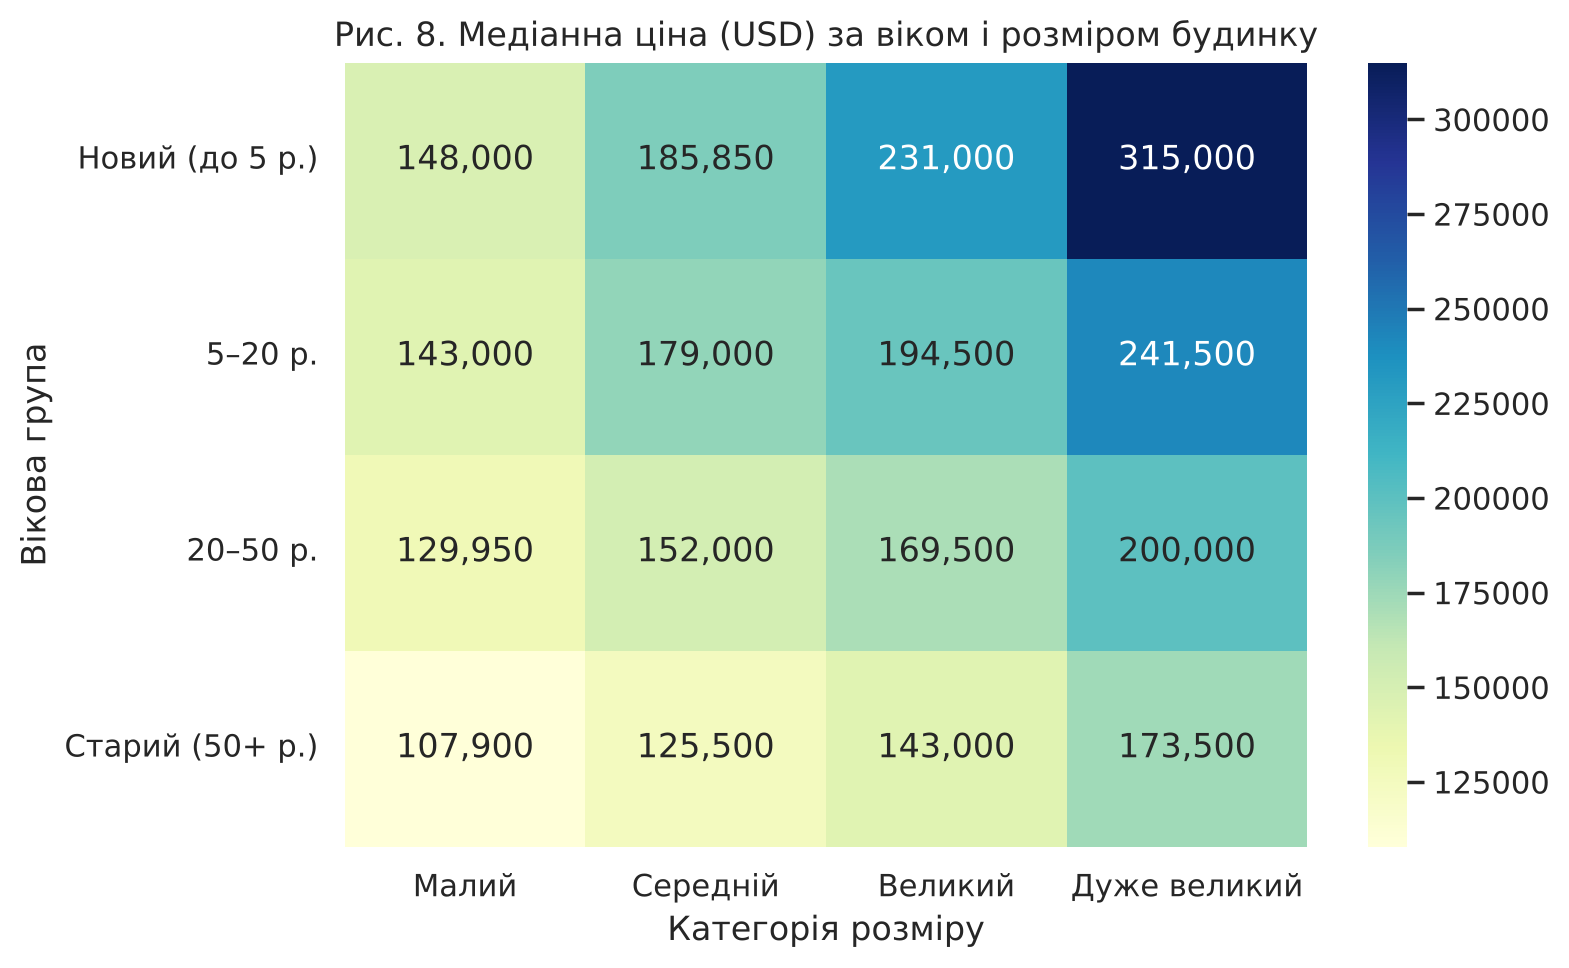

In [45]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(pivot_age_size, annot=True, fmt=",.0f", cmap="YlGnBu", ax=ax)
ax.set_title("Рис. 8. Медіанна ціна (USD) за віком і розміром будинку")
ax.set_xlabel("Категорія розміру")
ax.set_ylabel("Вікова група")
fig.tight_layout()
fig.savefig(FIG_DIR / "08_pivot_age_size_heatmap.png", dpi=150)
plt.show()

**Висновок.** Теплова карта наочно показує зведену таблицю з розділу 7.1: колір темнішає вправо (більші будинки дорожчі) і вгору (новіші будинки дорожчі). Найдорожча комбінація — нові дуже великі будинки (315 000 USD), найдешевша — старі малі (107 900 USD). Різниця за розміром у нових будинках більша, ніж у старих, тобто вплив площі посилюється з новизною.

In [46]:
# Збереження результатів: об'єднана таблиця й агрегати для звіту та Tableau
merged.to_csv("../data/processed/ames_analytic.csv", index=False)
Path("../results/exports").mkdir(parents=True, exist_ok=True)
by_nbhd.to_csv("../results/exports/by_neighborhood.csv")
yearly.to_csv("../results/exports/yearly_dynamics.csv")
pivot_age_size.to_csv("../results/exports/pivot_age_size.csv")
corr_price.round(3).to_csv("../results/exports/correlation_with_price.csv", header=["corr_with_SalePrice"])
print("Збережено: ames_analytic.csv та 4 файли в results/exports")

Збережено: ames_analytic.csv та 4 файли в results/exports


## 11. Експорт даних для Tableau Public

Для дашборда потрібна одна плоска таблиця з вибраними ознаками. Експортуємо її у `results/tableau/ames_tableau.csv`.

In [47]:
tableau_cols = [
    "Id", "NeighborhoodName", "YrSold", "MoSold", "SaleDate", "SalePrice", "PricePerSqFt",
    "GrLivArea", "TotalSF", "YearBuilt", "HouseAge", "AgeGroup", "SizeCategory",
    "OverallQual", "SaleCondition", "BldgType", "DwellingGroup", "HasGarage", "IsAnomaly",
]
tableau_df = merged[tableau_cols].copy()
tableau_df["SaleDate"] = tableau_df["SaleDate"].dt.strftime("%Y-%m-%d")
tableau_df["PricePerSqFt"] = tableau_df["PricePerSqFt"].round(2)
Path("../results/tableau").mkdir(parents=True, exist_ok=True)
tableau_df.to_csv("../results/tableau/ames_tableau.csv", index=False)
print("Рядків:", len(tableau_df), "| колонок:", tableau_df.shape[1])
tableau_df.head(3)

Рядків: 1460 | колонок: 19


,Id,NeighborhoodName,YrSold,MoSold,SaleDate,SalePrice,PricePerSqFt,GrLivArea,TotalSF,YearBuilt,HouseAge,AgeGroup,SizeCategory,OverallQual,SaleCondition,BldgType,DwellingGroup,HasGarage,IsAnomaly
0,1,College Creek,2008,2,2008-02-01,208500,121.93,1710,2566,2003,5,Новий (до 5 р.),Великий,7,Normal,1Fam,2 поверхи,1,0
1,2,Veenker,2007,5,2007-05-01,181500,143.82,1262,2524,1976,31,20–50 р.,Середній,6,Normal,1Fam,1 поверх,1,0
2,3,College Creek,2008,9,2008-09-01,223500,125.14,1786,2706,2001,7,5–20 р.,Дуже великий,7,Normal,1Fam,2 поверхи,1,0


Далі: інтерактивна панель у Tableau Public, підсумкові висновки та пояснювальна записка.